In [2]:
import pandas as pd
import numpy as np

# 1. Load your NYC Yellow Taxi CSV
df = pd.read_csv(r"D:\Datasets\archive\data.csv", low_memory=False)
print(f"Raw dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

# 2. Remove duplicates & rows with missing critical fields
df = df.drop_duplicates().copy()
df = df.dropna(subset=["tpep_pickup_datetime", "tpep_dropoff_datetime", "payment_type", "fare_amount", "total_amount"]).copy()

# 3. Fill missing passenger_count with median (1) and congestion_surcharge with 0
df["passenger_count"] = df["passenger_count"].fillna(df["passenger_count"].median())
if "congestion_surcharge" in df.columns:
    df["congestion_surcharge"] = df["congestion_surcharge"].fillna(0)

# 4. Parse datetimes & engineer business metrics
df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"])
df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"])
df["trip_duration_min"] = np.round((df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60, 2)
df["pickup_hour"] = df["tpep_pickup_datetime"].dt.hour
df["tip_pct"] = np.where(df["fare_amount"] > 0, np.round((df["tip_amount"] / df["fare_amount"]) * 100, 2), 0)

# Map standard TLC payment codes to readable labels
payment_map = {1: "Credit Card", 2: "Cash", 3: "No Charge", 4: "Dispute", 5: "Unknown", 6: "Voided"}
df["payment_label"] = df["payment_type"].map(payment_map).fillna("Other")

# 5. Filter out anomalous records (zero/negative fares, negative duration, or >180 min outliers)
df = df[
    (df["fare_amount"] > 0) &
    (df["total_amount"] > 0) &
    (df["trip_distance"] > 0) &
    (df["trip_duration_min"].between(1, 180))
].copy()

df.to_csv("nyc_yellow_taxi_clean.csv", index=False)
print(f"Cleaned dataset saved: {df.shape[0]:,} valid records")

Raw dataset loaded: 6,405,008 rows, 18 columns
Cleaned dataset saved: 6,216,720 valid records


In [3]:
import sqlite3
import pandas as pd

# Use 'df' directly from memory (no slow CSV reload!)
conn = sqlite3.connect(":memory:")
df.to_sql("yellow_taxi", conn, index=False, if_exists="replace")

q_payment = """
SELECT 
    payment_label AS Payment_Method,
    COUNT(*) AS Total_Trips,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM yellow_taxi), 2) AS Trip_Share_Pct,
    ROUND(AVG(trip_distance), 2) AS Avg_Distance_Miles,
    ROUND(AVG(total_amount), 2) AS Avg_Total_Fare,
    ROUND(AVG(tip_pct), 2) AS Avg_Tip_Pct
FROM yellow_taxi
GROUP BY payment_label
ORDER BY Total_Trips DESC;
"""
print("--- Payment Method & Tipping Analysis (6.4M+ Trips) ---")
print(pd.read_sql_query(q_payment, conn))

q_zones = """
SELECT 
    PULocationID AS Pickup_Zone_ID,
    COUNT(*) AS Trip_Volume,
    ROUND(SUM(total_amount), 2) AS Total_Revenue,
    ROUND(AVG(total_amount), 2) AS Avg_Fare,
    ROUND(AVG(trip_duration_min), 2) AS Avg_Duration_Min
FROM yellow_taxi
GROUP BY PULocationID
ORDER BY Total_Revenue DESC
LIMIT 10;
"""
print("\n--- Top 10 Revenue-Generating Pickup Zones ---")
print(pd.read_sql_query(q_zones, conn))

conn.close()

--- Payment Method & Tipping Analysis (6.4M+ Trips) ---
  Payment_Method  Total_Trips  Trip_Share_Pct  Avg_Distance_Miles  \
0    Credit Card      4632900           74.52                2.91   
1           Cash      1556261           25.03                2.80   
2      No Charge        19998            0.32                3.45   
3        Dispute         7561            0.12                3.61   

   Avg_Total_Fare  Avg_Tip_Pct  
0           19.30        26.22  
1           15.57         0.00  
2           17.76         0.03  
3           18.27         0.02  

--- Top 10 Revenue-Generating Pickup Zones ---
   Pickup_Zone_ID  Trip_Volume  Total_Revenue  Avg_Fare  Avg_Duration_Min
0             132       204738    11002516.99     53.74             33.40
1             138       130262     5369409.51     41.22             27.06
2             161       278222     4833105.57     17.37             13.23
3             237       289570     4182268.61     14.44             10.30
4             2

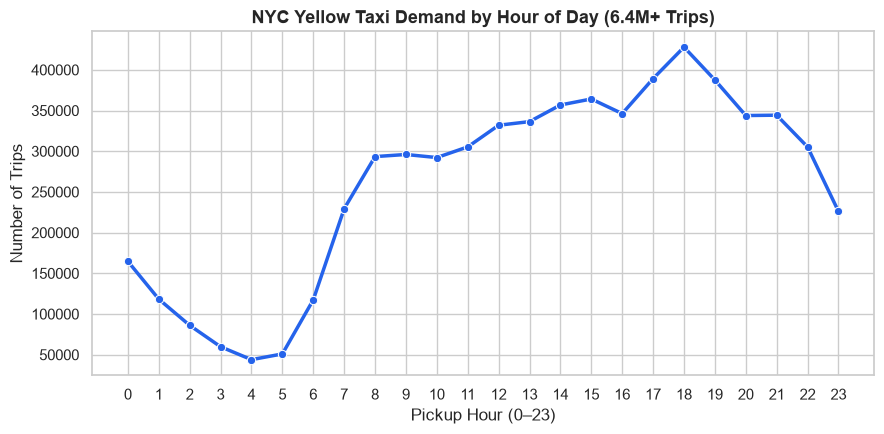

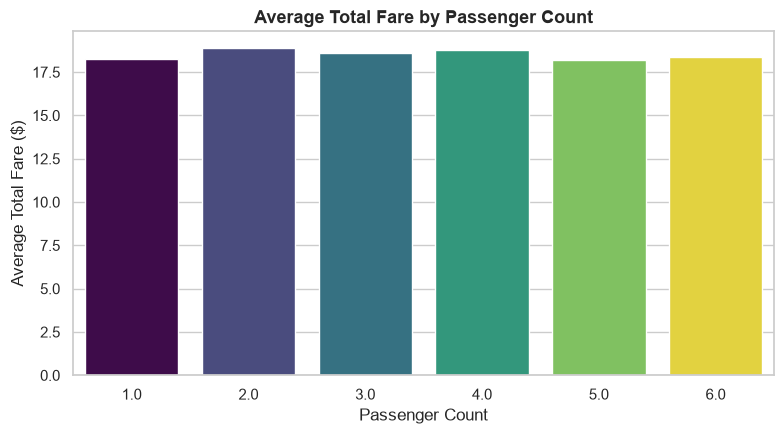

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Chart 1: Hourly Trip Demand Curve
hourly = df.groupby("pickup_hour")["total_amount"].count().reset_index(name="Trip_Count")

plt.figure(figsize=(9, 4.5))
sns.lineplot(data=hourly, x="pickup_hour", y="Trip_Count", marker="o", linewidth=2.5, color="#2563eb")
plt.title("NYC Yellow Taxi Demand by Hour of Day (6.4M+ Trips)", fontsize=13, fontweight="bold")
plt.xlabel("Pickup Hour (0–23)")
plt.ylabel("Number of Trips")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("hourly_taxi_demand.png", dpi=150)
plt.show()

# Chart 2: Average Fare by Passenger Count
pax_fare = df[df["passenger_count"].between(1, 6)].groupby("passenger_count")["total_amount"].mean().reset_index()

plt.figure(figsize=(8, 4.5))
sns.barplot(data=pax_fare, x="passenger_count", y="total_amount", hue="passenger_count", palette="viridis", legend=False)
plt.title("Average Total Fare by Passenger Count", fontsize=13, fontweight="bold")
plt.xlabel("Passenger Count")
plt.ylabel("Average Total Fare ($)")
plt.tight_layout()
plt.savefig("fare_by_passengers.png", dpi=150)
plt.show()